Iteration: 1 Best Distance: 26.83
Iteration: 2 Best Distance: 26.83
Iteration: 3 Best Distance: 26.83
Iteration: 4 Best Distance: 26.83
Iteration: 5 Best Distance: 26.83
Iteration: 6 Best Distance: 26.83
Iteration: 7 Best Distance: 26.83
Iteration: 8 Best Distance: 26.83
Iteration: 9 Best Distance: 26.83
Iteration: 10 Best Distance: 26.83
Iteration: 11 Best Distance: 26.83
Iteration: 12 Best Distance: 26.83
Iteration: 13 Best Distance: 26.83
Iteration: 14 Best Distance: 26.83
Iteration: 15 Best Distance: 26.83
Iteration: 16 Best Distance: 26.83
Iteration: 17 Best Distance: 26.83
Iteration: 18 Best Distance: 26.83
Iteration: 19 Best Distance: 26.83
Iteration: 20 Best Distance: 26.83
Iteration: 21 Best Distance: 26.83
Iteration: 22 Best Distance: 26.83
Iteration: 23 Best Distance: 26.83
Iteration: 24 Best Distance: 26.83
Iteration: 25 Best Distance: 26.83
Iteration: 26 Best Distance: 26.83
Iteration: 27 Best Distance: 26.83
Iteration: 28 Best Distance: 26.83
Iteration: 29 Best Distance: 

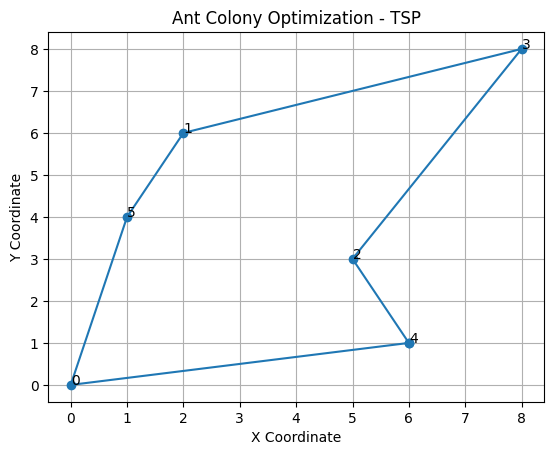

In [1]:

import numpy as np
import matplotlib.pyplot as plt

cities = np.array([
    [0, 0],
    [2, 6],
    [5, 3],
    [8, 8],
    [6, 1],
    [1, 4]
])

n_cities = len(cities)
n_ants = 10
iterations = 100

alpha = 1
beta = 2
rho = 0.5
Q = 100

distance = np.zeros((n_cities, n_cities))

for i in range(n_cities):
    for j in range(n_cities):
        distance[i][j] = np.linalg.norm(
            cities[i] - cities[j]
        )

pheromone = np.ones((n_cities, n_cities))

best_route = None
best_distance = float('inf')

for iteration in range(iterations):

    all_routes = []
    all_distances = []

    for ant in range(n_ants):

        start = np.random.randint(n_cities)
        route = [start]

        while len(route) < n_cities:

            current = route[-1]

            probabilities = []

            for city in range(n_cities):
                if city not in route:
                    value = (
                        pheromone[current][city] ** alpha
                        * (1 / distance[current][city]) ** beta
                    )
                else:
                    value = 0

                probabilities.append(value)

            probabilities = np.array(probabilities)
            probabilities = probabilities / probabilities.sum()

            next_city = np.random.choice(
                n_cities, p=probabilities
            )

            route.append(next_city)

        route.append(start)

        total_distance = sum(
            distance[route[i]][route[i + 1]]
            for i in range(n_cities)
        )

        all_routes.append(route)
        all_distances.append(total_distance)

        if total_distance < best_distance:
            best_distance = total_distance
            best_route = route.copy()

    pheromone *= (1 - rho)

    for route, length in zip(all_routes, all_distances):

        for i in range(n_cities):
            a = route[i]
            b = route[i + 1]

            pheromone[a][b] += Q / length
            pheromone[b][a] += Q / length

    print("Iteration:", iteration + 1,
          "Best Distance:", round(best_distance, 2))

print("Best Route:", best_route)
print("Shortest Distance:", round(best_distance, 2))

route_points = cities[best_route]

plt.plot(route_points[:, 0], route_points[:, 1], 'o-')

for i in range(n_cities):
    plt.text(cities[i][0], cities[i][1], str(i))

plt.title("Ant Colony Optimization - TSP")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid()
plt.show()
